In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from clima_ecuador import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
R = json.loads(config.RESULTADOS.read_text(encoding="utf-8"))
def figura(nombre, ancho=950):
    display(Image(filename=str(config.FIGURAS / nombre), width=ancho))
def reporte(nombre):
    return pd.read_csv(config.REPORTES / nombre)

# 03 · Tendencias y anomalías 1980–2024

**Pregunta:** ¿se está calentando el Ecuador? ¿llueve más o menos? ¿y cuánto podemos confiar en la respuesta?

**Método**
* Anomalía = valor − normal 1981–2010 del mismo mes (o año).
* **Mann-Kendall**: ¿hay una tendencia monótona? No supone normalidad ni linealidad.
* **Pendiente de Sen**: mediana de las pendientes entre todos los pares de años, robusta a años extremos (1997-98).
* **Autocorrelación**: un año cálido suele seguir a otro. Eso infla la significancia del test original.
  Se corrige con **Hamed y Rao (1998)**, aplicada solo cuando hace el test más conservador (factor ≥ 1).
* **Benjamini-Hochberg** para 22 ciudades a la vez.

## Ejemplo paso a paso: Quito

In [2]:
from clima_ecuador import tendencias
anual = pd.read_parquet(config.MENSUAL).assign(anio=lambda d: d["mes"].dt.year)
quito = anual[anual["punto"] == "Quito"].groupby("anio")["tmed"].mean()
for corr in ["ninguna", "hamed_rao", "yue_wang"]:
    r = tendencias.mann_kendall(quito.to_numpy(), correccion=corr, factor_minimo=1 if corr == "hamed_rao" else None)
    print(f"{corr:<10} S={r.s:+.0f}  Z={r.z:5.2f}  p={r.p:.6f}  Sen={r.pendiente * 10:+.3f} °C/década "
          f"(IC {r.ic_bajo * 10:+.3f} a {r.ic_alto * 10:+.3f})  factor={r.n_efectivo_factor:.2f}")

ninguna    S=+512  Z= 5.00  p=0.000001  Sen=+0.334 °C/década (IC +0.212 a +0.438)  factor=1.00
hamed_rao  S=+512  Z= 4.01  p=0.000061  Sen=+0.334 °C/década (IC +0.196 a +0.463)  factor=1.56
yue_wang   S=+512  Z= 7.08  p=0.000000  Sen=+0.334 °C/década (IC +0.243 a +0.412)  factor=0.50


La pendiente es la misma (+0,33 °C/década); cambia la incertidumbre. El factor 1,56 dice que la varianza de S
es 56 % mayor de lo que supone el test original: hay menos años "independientes" que 45.

Yue-Wang, en cambio, da un factor de 0,50 (usa la autocorrelación de los valores en todos los rezagos, y los rezagos
largos salen negativos por los ciclos de El Niño): **haría el test más permisivo que el original**. Por eso el
proyecto reporta Hamed-Rao, que solo usa rezagos significativos, y con un piso de 1.

## Todas las ciudades

In [3]:
t = reporte("tendencias_ciudades.csv")
tmed = t[t["variable"] == "tmed"].sort_values("pendiente_decada", ascending=False)
tmed[["punto", "region", "pendiente_decada", "ic_bajo_decada", "ic_alto_decada", "cambio_total",
      "p_original", "p_hamed_rao", "p_fdr", "factor_hr"]].round(4)

,punto,region,pendiente_decada,ic_bajo_decada,ic_alto_decada,cambio_total,p_original,p_hamed_rao,p_fdr,factor_hr
133,Santo Domingo,Costa,0.348,0.186,0.500,1.530,0.000,0.000,0.001,1.649
112,Quito,Sierra,0.334,0.196,0.463,1.471,0.000,0.000,0.001,1.556
35,Ibarra,Sierra,0.310,0.179,0.426,1.364,0.000,0.000,0.001,1.498
119,Riobamba,Sierra,0.286,0.107,0.474,1.258,0.000,0.002,0.004,1.768
140,Tena,Amazonía,0.273,0.146,0.384,1.201,0.000,0.000,0.001,1.681
7,Coca,Amazonía,0.273,0.140,0.397,1.200,0.000,0.000,0.001,1.673
70,Manta,Costa,0.266,0.050,0.472,1.172,0.002,0.015,0.021,1.679
42,Latacunga,Sierra,0.260,0.135,0.386,1.144,0.000,0.001,0.001,1.617
77,Nueva Loja,Amazonía,0.259,0.133,0.385,1.141,0.000,0.000,0.001,1.641
84,Portoviejo,Costa,0.257,-0.014,0.545,1.131,0.007,0.066,0.072,2.133


In [4]:
resumen = t.groupby("variable").agg(sube=("tendencia", lambda s: (s == "sube").sum()),
                                     baja=("tendencia", lambda s: (s == "baja").sum()),
                                     sig_sin_corregir=("p_original", lambda p: (p < 0.05).sum()),
                                     sig_fdr=("significativa_fdr", "sum"))
resumen

,sube,baja,sig_sin_corregir,sig_fdr
variable,,,,
humedad,0,0,3,0
precip,3,1,6,1
radiacion,0,2,2,0
tmax,12,0,16,6
tmed,18,0,20,18
tmin,19,0,20,19
viento_max,8,2,13,8


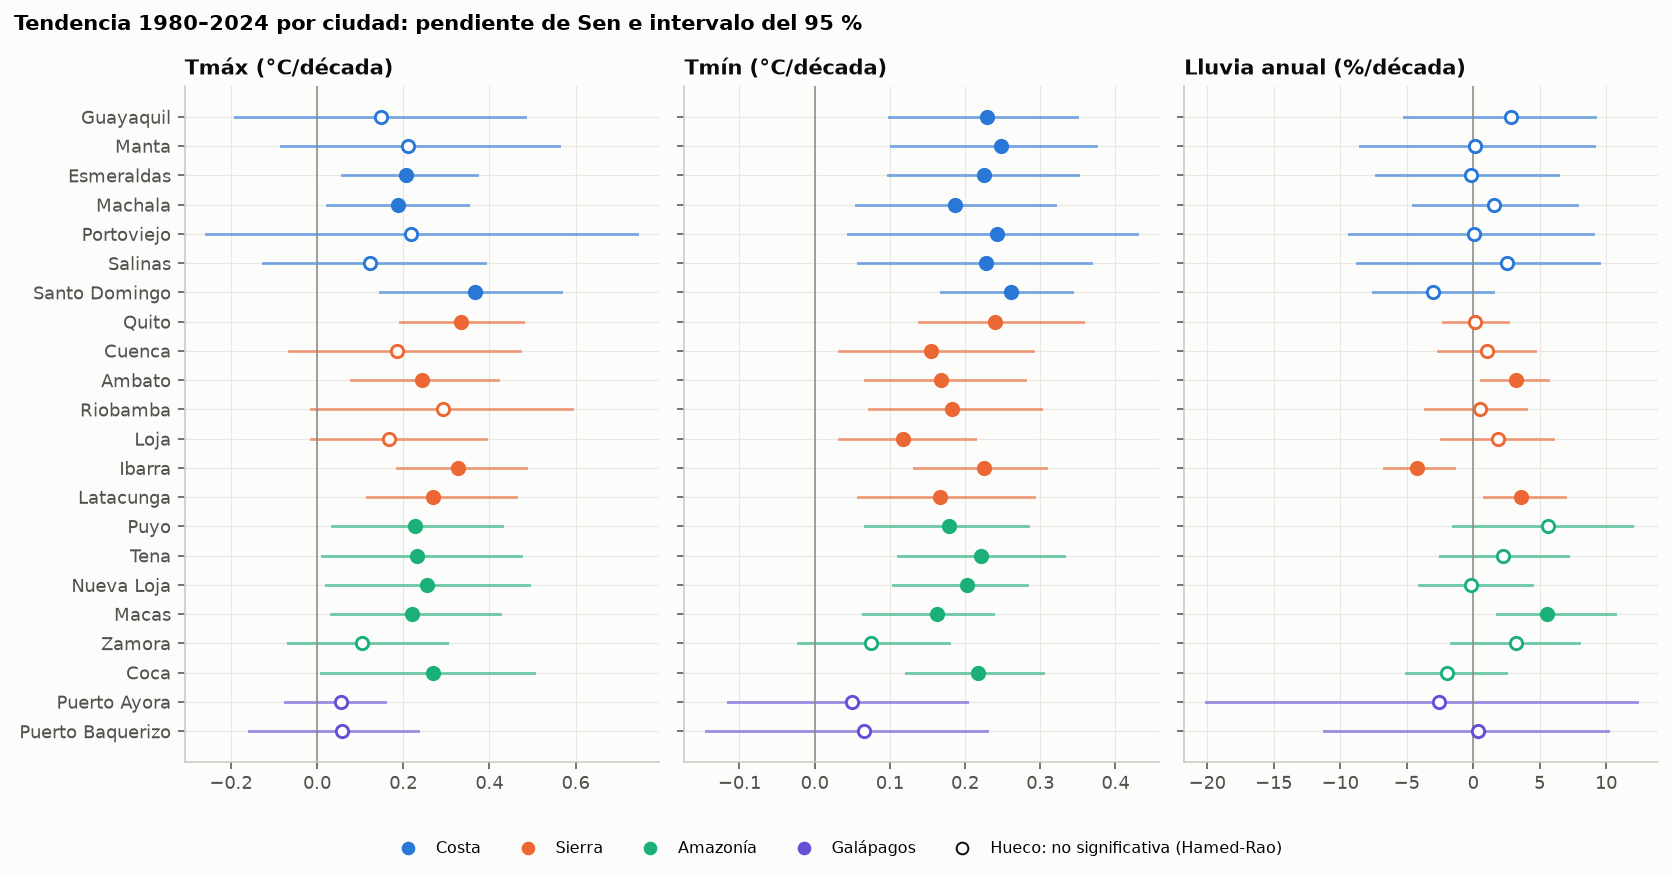

In [5]:
figura("07_tendencias_ciudades.png")

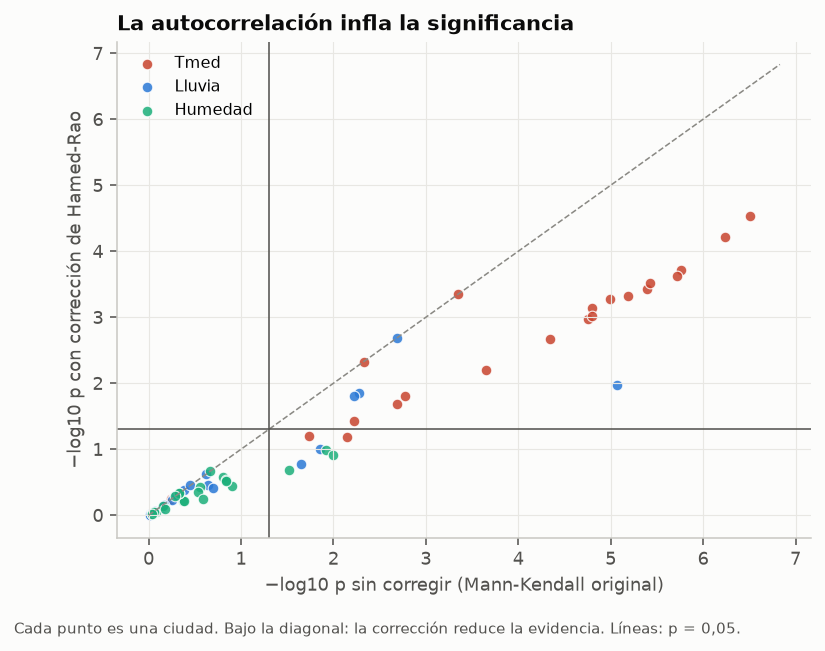

In [6]:
figura("08_correccion_autocorrelacion.png", 650)

* **18 de 22 ciudades** se calientan de forma significativa, y las 18 siguen significativas con FDR.
  Sin corregir la autocorrelación serían 20: **Salinas y Portoviejo** pierden la significancia.
* Las **noches se calientan en más sitios que los días**: Tmín significativa en 19 ciudades (todas con FDR), Tmáx en 12 (6 con FDR).
* **Galápagos no muestra tendencia** (+0,04 a +0,06 °C/década, p ≈ 0,5): su temperatura la domina El Niño.
  Ahí el factor de Hamed-Rao sale < 1 (autocorrelación negativa por el ciclo de 3–7 años de ENOS) y, sin piso, el
  test se volvería *menos* exigente que el original: Tmín de Puerto Ayora pasaría de p = 0,49 a p = 0,07.
* La **lluvia** no tiene tendencia en 18 de 22 ciudades. Suben Ambato, Latacunga y Macas; baja Ibarra.

## Regiones y país

In [7]:
reporte("tendencias_regiones.csv").query("variable in ['tmed', 'tmax', 'tmin', 'precip']")[
    ["region", "variable", "pendiente_decada", "ic_bajo_decada", "ic_alto_decada", "p_original", "p_hamed_rao"]].round(4)

,region,variable,pendiente_decada,ic_bajo_decada,ic_alto_decada,p_original,p_hamed_rao
0,Amazonía,tmed,0.237,0.105,0.352,0.000,0.001
1,Amazonía,tmax,0.216,0.038,0.414,0.002,0.022
2,Amazonía,tmin,0.182,0.080,0.272,0.000,0.001
3,Amazonía,precip,72.143,-36.241,197.967,0.062,0.197
7,Costa,tmed,0.257,0.054,0.468,0.001,0.011
8,Costa,tmax,0.209,-0.016,0.430,0.023,0.078
9,Costa,tmin,0.238,0.097,0.345,0.001,0.001
10,Costa,precip,-0.037,-102.207,95.983,1.000,1.000
14,Galápagos,tmed,0.055,-0.121,0.221,0.500,0.500
15,Galápagos,tmax,0.048,-0.109,0.208,0.463,0.463


In [8]:
reporte("tendencias_nacional.csv")[["variable", "pendiente_decada", "cambio_total", "p_original", "p_hamed_rao"]].round(4)

,variable,pendiente_decada,cambio_total,p_original,p_hamed_rao
0,tmed,0.240,1.055,0.000,0.002
1,tmax,0.228,1.004,0.002,0.022
2,tmin,0.184,0.812,0.000,0.002
3,precip_pct,1.017,4.476,0.538,0.538


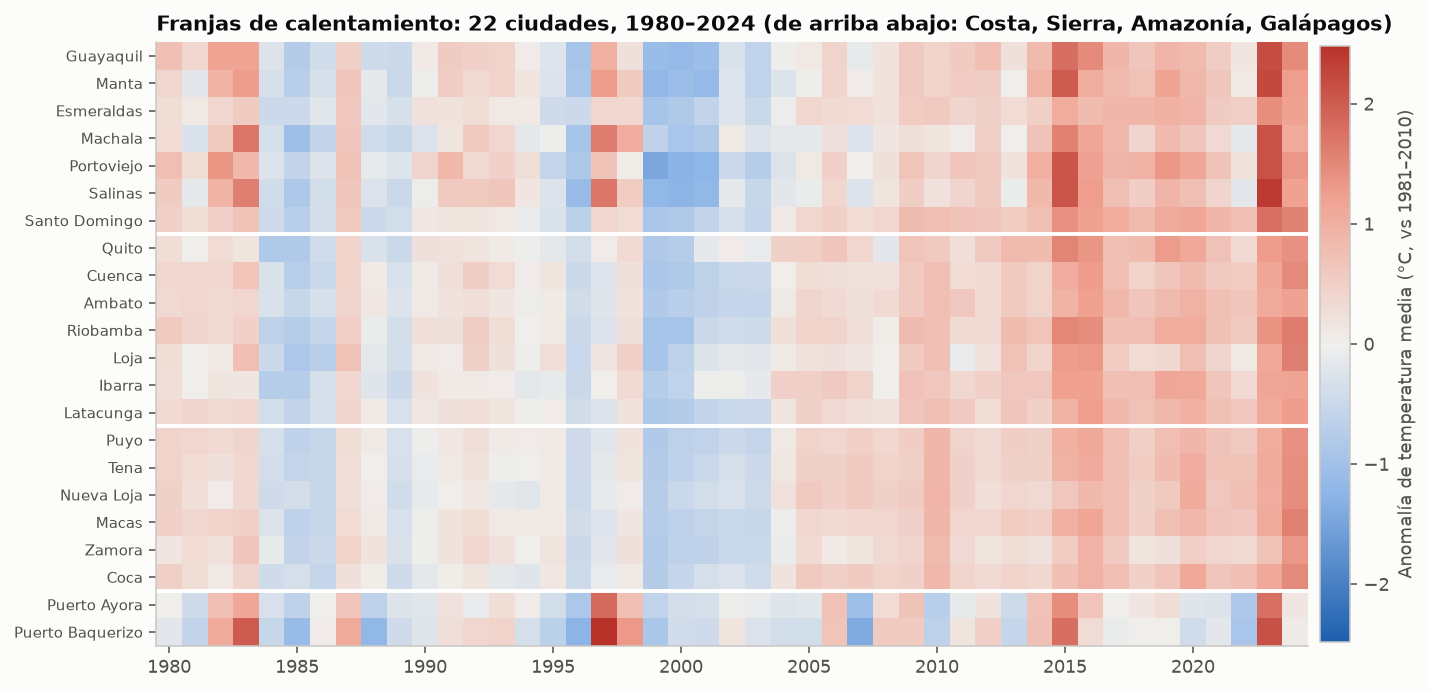

In [9]:
figura("05_franjas_calentamiento.png")

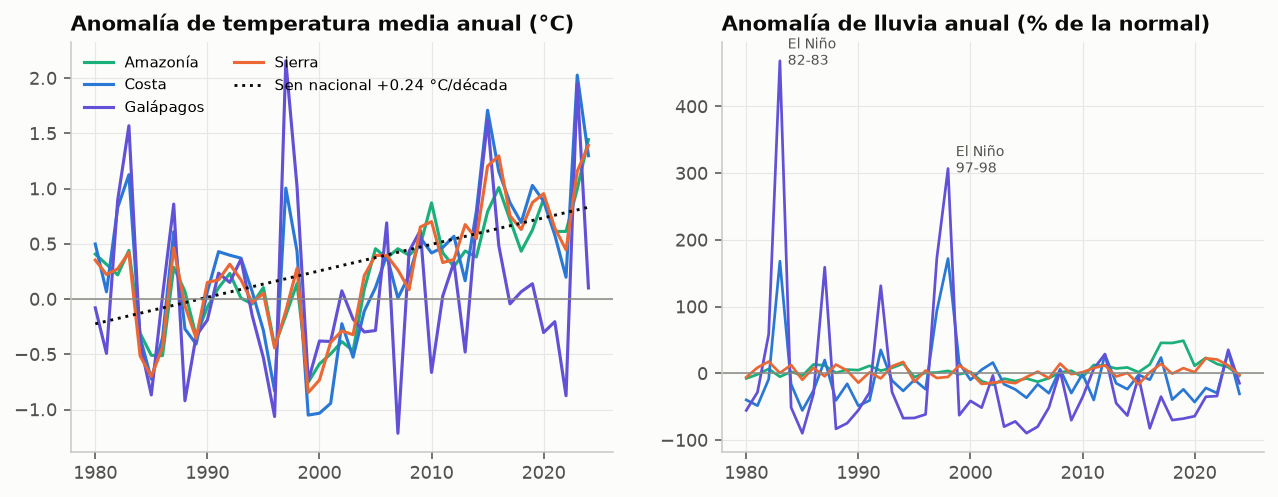

,anio,tmed
0,2023,1.462
1,2015,1.290
2,2024,1.258
3,2016,1.100
4,2020,0.805


In [10]:
figura("06_anomalias_regiones.png")
pd.DataFrame(R["anios_mas_calidos"])

Los 4 años más cálidos son **2023, 2015, 2024 y 2016**: todos con El Niño fuerte encima de la tendencia.
1999–2001 (La Niña larga) fueron los más fríos de la serie.

## ¿Tendencia o salto? (test de Pettitt)

Un cambio en las observaciones que asimila el reanálisis (por ejemplo, nuevos satélites) puede crear un **escalón**
artificial. El test de Pettitt busca el punto de cambio más probable.

In [11]:
pett = reporte("pettitt_tmed.csv")
print("Con la tendencia:", (pett["p"] < 0.05).sum(), "ciudades con cambio significativo, años:",
      pett.loc[pett["p"] < 0.05, "anio_cambio"].value_counts().to_dict())
print("Quitando la recta de Sen:", (pett["p_sin_tendencia"] < 0.05).sum(), "ciudades con salto significativo")

Con la tendencia: 20 ciudades con cambio significativo, años: {2005: 9, 2009: 8, 2004: 2, 2008: 1}
Quitando la recta de Sen: 0 ciudades con salto significativo


Con la serie original Pettitt "encuentra" un cambio en 2004–2009 en 20 ciudades, pero eso es lo que hace con
cualquier tendencia (parte la serie por la mitad). Quitando la tendencia **ningún** salto es significativo: los datos
son coherentes con un calentamiento gradual, no con un escalón artificial del reanálisis.

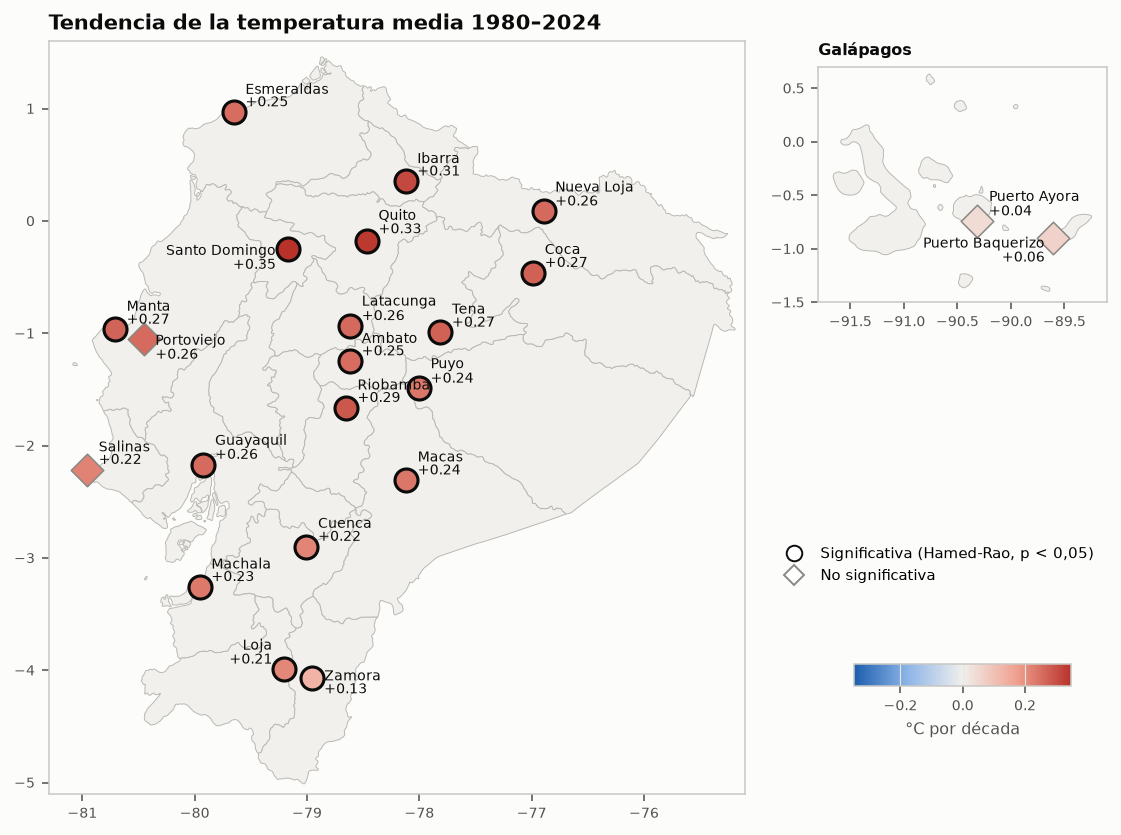

In [12]:
figura("16_mapa_tendencia_temperatura.png", 800)

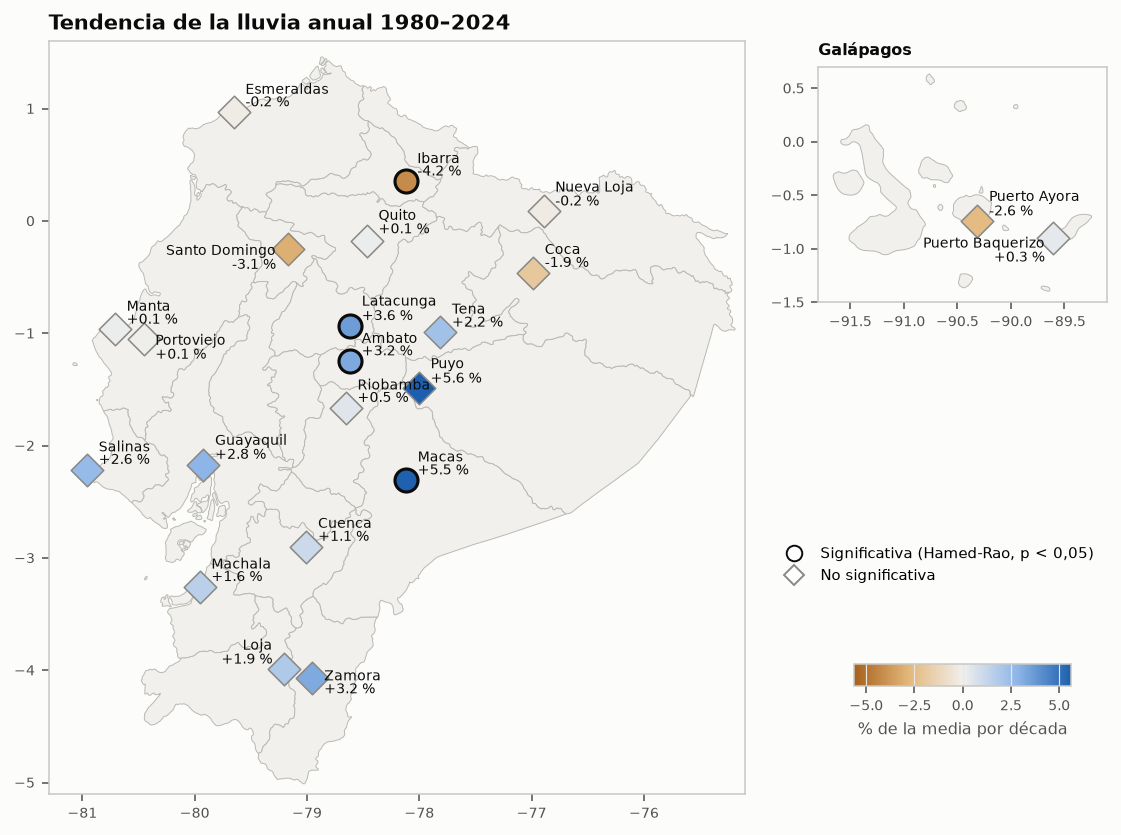

In [13]:
figura("17_mapa_tendencia_lluvia.png", 800)